# Movie data profiling and EDA

Profiles the two candidate datasets and prototypes the catalog features for retrieval.

- Catalog: [Chelikani2006/Movie-recommendation-data](https://huggingface.co/datasets/Chelikani2006/Movie-recommendation-data)
- Ratings: [Padmanav/movie-recommender-artifacts](https://huggingface.co/datasets/Padmanav/movie-recommender-artifacts) (optional, last)

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tiktoken

sys.path.insert(0, str(Path.cwd().parent))
from db import movie_index
from db.catalog import CATALOG_REPO, STREAMERS, build_catalog, fetch, is_placeholder, load_raw, parse_names

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({
    "figure.figsize": (10, 3.4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"
SOURCE_COLORS = {"legacy": BLUE, "2018+": ORANGE}

RATINGS_REPO = "Padmanav/movie-recommender-artifacts"


## Catalog dataset

In [ ]:
legacy = pd.read_csv(fetch(CATALOG_REPO, "movies_with_streaming.csv"), low_memory=False)
raw = load_raw()

assert list(legacy.columns) == list(raw.columns)
assert legacy.id.isin(raw.id).all()
raw["source"] = np.where(raw.id.isin(legacy.id), "legacy", "2018+")
raw["year"] = pd.to_datetime(raw.release_date, errors="coerce").dt.year
print(f"legacy file: {legacy.shape}, expanded file: {raw.shape}")
raw.groupby("source").year.agg(["size", "min", "max"])


legacy file: (45430, 34), expanded file: (57499, 36)


,size,min,max
source,,,
2018+,12069,2018.0,2026.0
legacy,45430,1874.0,2022.0


The expanded file contains every row of the streaming file plus about 12k movies released 2018-2026, so only the expanded file is used from here on. `source` marks which batch a row came from, because the two batches were collected differently.

In [ ]:
def profile(df: pd.DataFrame) -> pd.DataFrame:
    nulls = df.groupby("source").agg(lambda s: s.isna().mean() * 100).T.add_prefix("null%_")
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "example": df.apply(lambda s: str(s.dropna().iloc[0])[:50] if s.notna().any() else ""),
    }).join(nulls.round(1)).drop(index="source")


profile(raw)


,dtype,n_unique,example,null%_2018+,null%_legacy
adult,float64,2,0.0,100.0,0.0
belongs_to_collection,str,1695,"{'id': 10194, 'name': 'Toy Story Collection', 'pos",100.0,90.1
budget,float64,1223,30000000.0,100.0,0.0
genres,str,6206,"[{'id': 16, 'name': 'Animation'}, {'id': 35, 'name",0.1,0.0
homepage,str,7669,http://toystory.disney.com/toy-story,100.0,82.9
id,int64,57499,862,0.0,0.0
imdb_id,str,45403,tt0114709,100.0,0.1
original_language,str,99,en,0.0,0.0
original_title,str,54502,Toy Story,0.0,0.0
overview,str,56338,"Led by Woody, Andy's toys live happily in his room",0.2,2.1


In [ ]:
numeric = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
(raw.groupby("source")[numeric].agg(lambda s: (s == 0).mean() * 100).T.round(1)
    .rename(columns=lambda c: f"zero%_{c}"))


source,zero%_2018+,zero%_legacy
budget,0.0,80.4
revenue,100.0,83.7
runtime,0.6,3.4
popularity,0.0,0.1
vote_average,0.0,6.6
vote_count,0.0,6.4


In [ ]:
print("missing or placeholder overviews:", is_placeholder(raw.overview).sum())
for col in ["status", "adult", "video"]:
    print(raw[col].value_counts(dropna=False).to_dict())


missing or placeholder overviews: 1138
{'Released': 57061, 'Rumored': 229, 'Post Production': 93, nan: 81, 'In Production': 19, 'Planned': 14, 'Canceled': 2}
{0.0: 45411, nan: 12079, 1.0: 9}
{False: 57406, True: 93}


### Distributions

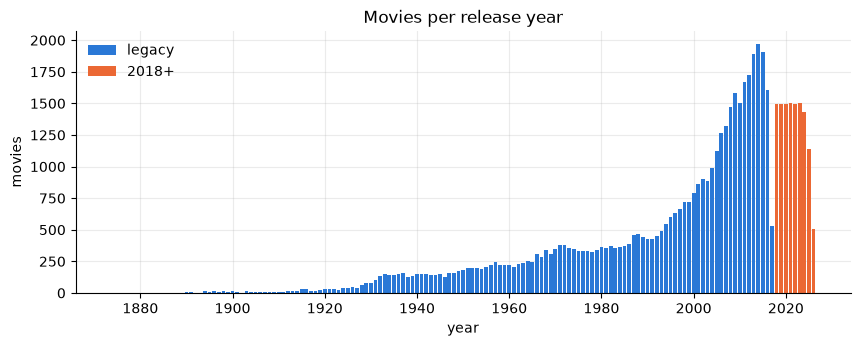

In [ ]:
fig, ax = plt.subplots()
for source, color in SOURCE_COLORS.items():
    counts = raw.loc[raw.source == source, "year"].value_counts().sort_index()
    ax.bar(counts.index, counts.values, width=0.8, color=color, label=source)
ax.set(title="Movies per release year", xlabel="year", ylabel="movies")
ax.legend(frameon=False)
plt.show()


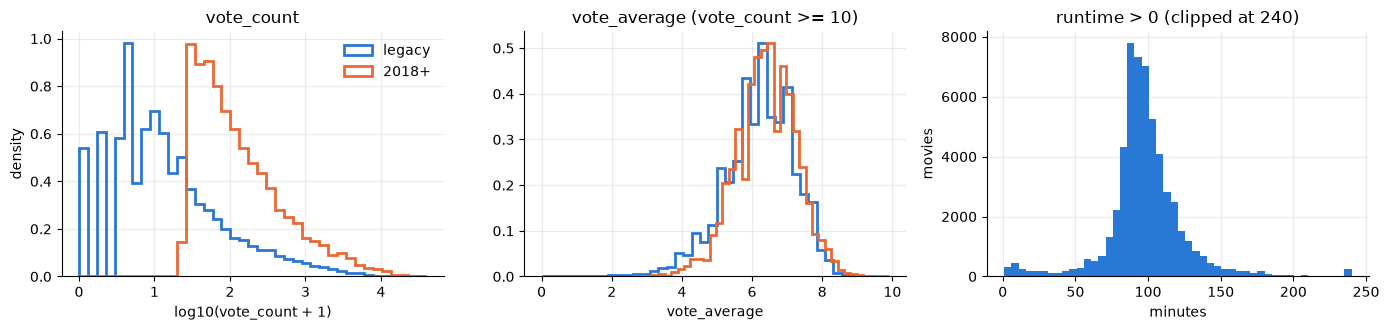

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
bins = np.linspace(0, 4.6, 40)
for source, color in SOURCE_COLORS.items():
    part = raw[raw.source == source]
    axes[0].hist(np.log10(part.vote_count + 1), bins=bins, histtype="step", lw=2, color=color, label=source, density=True)
    axes[1].hist(part.vote_average[part.vote_count >= 10], bins=40, histtype="step", lw=2, color=color, label=source, density=True)
axes[0].set(title="vote_count", xlabel="log10(vote_count + 1)", ylabel="density")
axes[1].set(title="vote_average (vote_count >= 10)", xlabel="vote_average")
axes[2].hist(raw.runtime[raw.runtime > 0].clip(0, 240), bins=48, color=BLUE)
axes[2].set(title="runtime > 0 (clipped at 240)", xlabel="minutes", ylabel="movies")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()


In [ ]:
vote_bins = pd.cut(raw.vote_count, [24, 100, 1000, 5000, 40000])
raw.pivot_table(index=vote_bins, columns="source", values="popularity", aggfunc="median", observed=True).round(2)


source,2018+,legacy
vote_count,,
"(24, 100]",2.38,3.81
"(100, 1000]",3.84,8.18
"(1000, 5000]",10.17,13.33
"(5000, 40000]",19.21,26.88


Same vote_count band, very different `popularity`. The two batches were pulled from TMDB years apart, so raw popularity is not comparable across them. `vote_count` and `vote_average` hold up better.

In [ ]:
raw[["year", "runtime", "popularity", "vote_average", "vote_count"]].corr(method="spearman").round(2)


,year,runtime,popularity,vote_average,vote_count
year,1.00,0.09,0.36,0.11,0.47
runtime,0.09,1.00,0.30,0.20,0.29
popularity,0.36,0.30,1.00,0.26,0.89
vote_average,0.11,0.20,0.26,1.00,0.33
vote_count,0.47,0.29,0.89,0.33,1.00


### Genres, language, people

In [ ]:
raw["genre_list"] = raw.genres.map(parse_names)
genre_vocab = raw.explode("genre_list").groupby("genre_list").source.value_counts().unstack(fill_value=0)
genre_vocab.sort_values("legacy", ascending=False)


source,2018+,legacy
genre_list,,
Drama,5140,20244
Comedy,3774,13176
Thriller,2863,7619
Romance,1841,6730
Action,2070,6590
Horror,1854,4672
Crime,1391,4305
Documentary,849,3930
Adventure,1109,3490


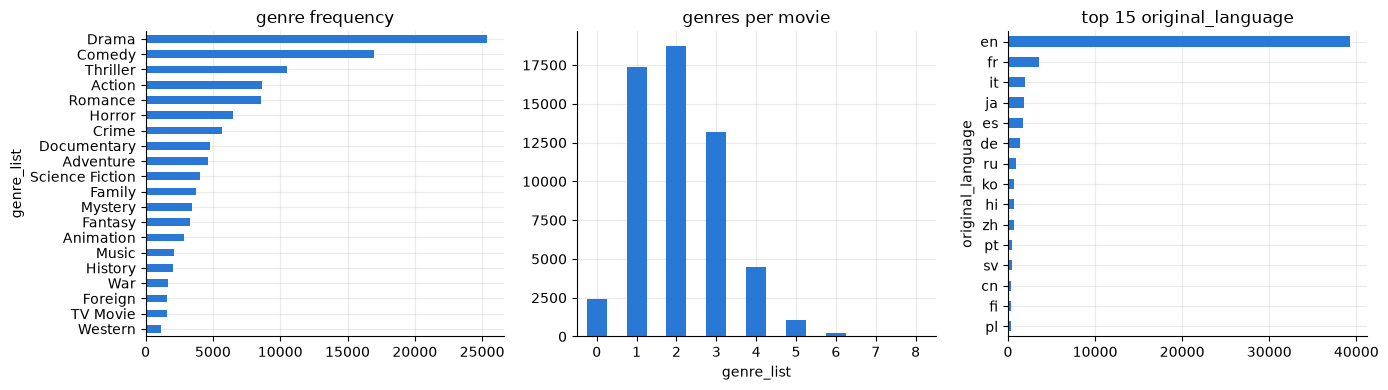

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
raw.genre_list.explode().value_counts().sort_values().plot.barh(ax=axes[0], color=BLUE, title="genre frequency")
raw.genre_list.str.len().value_counts().sort_index().plot.bar(ax=axes[1], color=BLUE, title="genres per movie", rot=0)
raw.original_language.value_counts().head(15).sort_values().plot.barh(ax=axes[2], color=BLUE, title="top 15 original_language")
plt.tight_layout()
plt.show()


`genres_clean` splits multi-word genres ("Science Fiction" becomes "Science" and "Fiction") and uses a different delimiter per batch, so genres are parsed from the raw `genres` column instead. The parsed vocabulary is the same 20 TMDB genres in both batches.

In [ ]:
people = pd.DataFrame({
    "source": raw.source,
    "cast_n": raw.main_cast.map(parse_names).str.len(),
    "director_n": raw.director.map(parse_names).str.len(),
})
people.groupby("source").agg(["mean", "median", "max"]).round(2)


cast_n            director_n           
         mean median max       mean median max
source                                        
2018+    9.41   10.0  11       1.10    1.0  13
legacy   1.87    2.0  10       1.08    1.0  42

In [ ]:
profile_has_cast = raw.apply(lambda r: isinstance(r.main_cast, str) and r.main_cast in r.movie_profile, axis=1)
pd.crosstab(raw.source, profile_has_cast, normalize="index").round(3).rename(columns={True: "profile_has_cast", False: "no_cast"})


col_0,no_cast,profile_has_cast
source,,
2018+,0.005,0.995
legacy,0.984,0.016


The two batches differ in shape: legacy rows carry 2 cast names and a `movie_profile` of genres plus overview, while 2018+ rows carry up to 10 names and also fold cast and director into `movie_profile`. The proposal rebuilds the embedding text from parsed columns so every movie gets the same template.

### Streaming flags and duplicates

In [ ]:
has_stream = raw[STREAMERS].any(axis=1)
pd.DataFrame({"movies": raw.groupby("source").size(), "with_streaming": has_stream.groupby(raw.source).sum()}).assign(
    pct=lambda d: (d.with_streaming / d.movies * 100).round(1))


,movies,with_streaming,pct
source,,,
2018+,12069,0,0.0
legacy,45430,3439,7.6


In [ ]:
dup_title = raw.title.duplicated(keep=False)
dup_title_year = raw.duplicated(["title", "year"], keep=False)
print(f"titles shared by >1 movie: {dup_title.sum()}, same title and year: {dup_title_year.sum()}")
raw.loc[dup_title_year, ["id", "imdb_id", "title", "year", "director", "vote_count"]].sort_values(["title", "year"]).head(10)


titles shared by >1 movie: 7926, same title and year: 180


,id,imdb_id,title,year,director,vote_count
20837,2966,tt0118248,"20,000 Leagues Under the Sea",1997.0,Rod Hardy,13.0
24091,2965,tt0118247,"20,000 Leagues Under the Sea",1997.0,Michael Anderson,3.0
30976,332976,tt3503840,Absolution,2015.0,Keoni Waxman,34.0
36123,315055,tt3442634,Absolution,2015.0,Petri Kotwica,2.0
15346,39641,tt1016321,Adrift,2009.0,Heitor Dhalia,34.0
16158,111396,tt1499639,Adrift,2009.0,Bùi Thạc Chuyên,3.0
19890,143800,tt2209300,Aftermath,2012.0,Władysław Pasikowski,20.0
24066,188839,tt1564368,Aftermath,2012.0,Peter Engert,19.0
48678,509635,NaN,Alone,2020.0,John Hyams,896.0
48794,661950,NaN,Alone,2020.0,Johnny Martin,213.0


## Catalog features

`build_catalog` in [db/catalog.py](../db/catalog.py) turns the raw rows into the features proposed in the doc, plus an `indexable` flag and the text that gets embedded.

In [ ]:
catalog = build_catalog(raw)
catalog.head(3).T


,0,1,2
tmdb_id,862,8844,15602
imdb_id,tt0114709,tt0113497,tt0113228
title,Toy Story,Jumanji,Grumpier Old Men
year,1995,1995,1995
genres,"[Animation, Comedy, Family]","[Adventure, Fantasy, Family]","[Romance, Comedy]"
overview,"Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear o...",When siblings Judy and Peter discover an enchanted board game that opens the door to a magical w...,A family wedding reignites the ancient feud between next-door neighbors and fishing buddies John...
tagline,NaN,Roll the dice and unleash the excitement!,Still Yelling. Still Fighting. Still Ready for Love.
director,[John Lasseter],[Joe Johnston],[Howard Deutch]
cast,"[Tom Hanks, Tim Allen]","[Robin Williams, Jonathan Hyde]","[Walter Matthau, Jack Lemmon]"
collection,Toy Story Collection,NaN,Grumpy Old Men Collection


In [ ]:
for t in catalog.loc[catalog.indexable].sample(3, random_state=7).embed_text:
    print(t, end="\n\n")
enc = tiktoken.get_encoding("cl100k_base")
tokens = catalog.loc[catalog.indexable, "embed_text"].map(lambda t: len(enc.encode(t)))
tokens.describe(percentiles=[0.5, 0.95, 0.99]).round(0)


I've Loved You So Long (2008). Genres: Drama. A woman struggles to interact with her family and find her place in society after spending fifteen years in prison.

From Up on Poppy Hill (2011). Genres: Animation, Drama. I look up as I walk... The story is set in 1963 in Yokohama. Kokuriko Manor sits on a hill overlooking the harbour. A 16 year-old girl, Umi, lives in that house. Every morning she raises a signal flag facing the sea. The flag means “I pray for safe voyages”. A 17 year-old boy, Shun, always sees this flag from the sea as he rides a tugboat to school. Gradually the pair are drawn to each other but they are faced with a sudden trial. Even so, they keep going without running from facing the hardships of reality.

Bed of Roses (1996). Genres: Drama, Romance. He gave her flowers. She gave him a chance. The seeds of love are planted when Lisa, a high-powered investment banker, receives flowers from a secret admirer. But when his fairy-tale fantasies clash with her workaholic wa

count    34661.0
mean        83.0
std         39.0
min         12.0
50%         74.0
95%        162.0
99%        213.0
max        398.0
Name: embed_text, dtype: float64

In [ ]:
base = raw.status.eq("Released") & raw.adult.ne(1) & catalog.overview.notna()
sizes = {n: (base & catalog.vote_count.ge(n)).groupby(raw.source).sum() for n in [0, 5, 10, 25, 50, 100]}
pd.DataFrame(sizes).T.assign(total=lambda d: d.sum(axis=1)).rename_axis("min vote_count")


source,2018+,legacy,total
min vote_count,,,
0,12040,43914,55954
5,12040,30313,42353
10,12040,22621,34661
25,12040,13686,25726
50,8559,9100,17659
100,5813,6045,11858


In [ ]:
cols = ["title", "year", "vote_average", "vote_count", "weighted_rating"]
catalog[catalog.indexable].nlargest(10, "weighted_rating")[cols]


,title,year,vote_average,vote_count,weighted_rating
57011,Project Hail Mary,2026,8.600,8057,8.494
57060,Swapped,2026,8.865,2214,8.483
46922,Parasite,2019,8.490,21395,8.451
57044,Michael,2026,8.625,4443,8.440
55851,Demon Slayer: Kimetsu no Yaiba Infinity Castle,2025,8.800,2211,8.430
57023,Avatar Aang: The Last Airbender,2026,9.100,1216,8.427
314,The Shawshank Redemption,1994,8.500,8358,8.404
834,The Godfather,1972,8.500,6024,8.369
45421,Spider-Man: Into the Spider-Verse,2018,8.401,17936,8.357
52918,Spider-Man: Across the Spider-Verse,2023,8.351,9327,8.272


`weighted_rating` shrinks each `vote_average` toward the vote-weighted catalog mean by `PRIOR_VOTES` (500, near the 90th percentile of `vote_count`), which keeps movies with only a few hundred votes out of the top 10. Releases from 2025-2026 still rank high on early votes. A single TMDB snapshot cannot correct that.

## Ratings dataset (optional)

A MovieLens subset with user ratings and prebuilt train/val/test splits. Kept last so it can be dropped without touching the catalog work.

In [ ]:
splits = {k: pd.read_parquet(fetch(RATINGS_REPO, f"data/splits/{k}.parquet")) for k in ["train", "val", "test"]}
ratings = pd.concat(splits, names=["split"]).reset_index(level=0).reset_index(drop=True)
ratings["tmdb_id"] = pd.to_numeric(ratings.tmdbId, errors="coerce").astype("Int64")
ratings.groupby("split").agg(rows=("rating", "size"), users=("user_id", "nunique"), movies=("movie_id", "nunique"), mean_rating=("rating", "mean")).round(3)


,rows,users,movies,mean_rating
split,,,,
test,177371,29441,6846,3.537
train,688779,29474,7642,3.555
val,73940,29441,5171,3.566


In [ ]:
train = splits["train"]
print("val/test users seen in train:", splits["val"].user_id.isin(train.user_id).mean(), splits["test"].user_id.isin(train.user_id).mean())
print("val/test movies seen in train:", splits["val"].movie_id.isin(train.movie_id).mean(), splits["test"].movie_id.isin(train.movie_id).mean())
print("duplicate (user, movie) pairs:", ratings.duplicated(["user_id", "movie_id"]).sum())
print("users per number of splits they appear in:", ratings.groupby("user_id").split.nunique().value_counts().to_dict())
print("columns:", list(ratings.columns))


val/test users seen in train: 1.0 1.0
val/test movies seen in train: 1.0 1.0
duplicate (user, movie) pairs: 0


users per number of splits they appear in: {3: 29441, 1: 33}
columns: ['split', 'imdbId', 'tmdbId', 'movie_id', 'user_id', 'rating', 'title', 'genres', 'posters', 'genre_list', 'user_idx', 'movie_idx', 'tmdb_id']


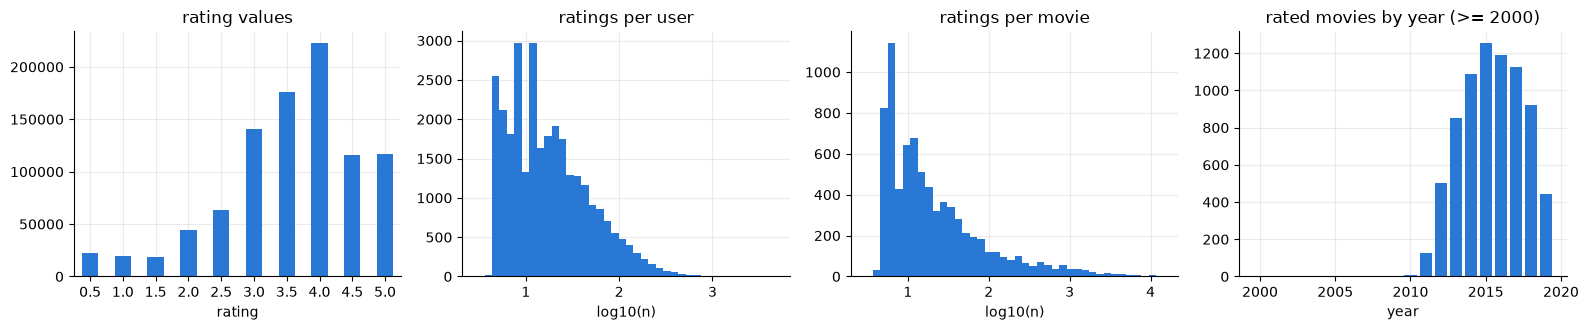

,count,mean,std,min,25%,50%,75%,max
per_user,29474.0,31.9,59.9,3.0,8.0,15.0,32.0,4678.0
per_movie,7642.0,123.0,619.7,3.0,7.0,14.0,39.0,14448.0


In [ ]:
per_user = ratings.groupby("user_id").size()
per_movie = ratings.groupby("movie_id").size()
rated_year = ratings.drop_duplicates("movie_id").title.str.extract(r"\((\d{4})\)\s*$")[0].astype(float)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0], color=BLUE, rot=0, title="rating values")
axes[1].hist(np.log10(per_user), bins=40, color=BLUE)
axes[1].set(title="ratings per user", xlabel="log10(n)")
axes[2].hist(np.log10(per_movie), bins=40, color=BLUE)
axes[2].set(title="ratings per movie", xlabel="log10(n)")
year_counts = rated_year[rated_year >= 2000].value_counts().sort_index()
axes[3].bar(year_counts.index, year_counts.values, color=BLUE)
axes[3].set(title="rated movies by year (>= 2000)", xlabel="year")
plt.tight_layout()
plt.show()
pd.DataFrame({"per_user": per_user.describe(), "per_movie": per_movie.describe()}).round(1).T


No timestamps, so the splits are a random per-user holdout: every val/test user and movie also appears in train. Rated movies are almost all 2011-2019 releases.

### Join coverage

In [ ]:
movies = ratings.groupby("movie_id").agg(imdb_id=("imdbId", "first"), tmdb_id=("tmdb_id", "first"), title=("title", "first"), n=("rating", "size"))
by_imdb = movies.imdb_id.isin(catalog.imdb_id.dropna())
by_tmdb = movies.tmdb_id.isin(catalog.tmdb_id)
pd.DataFrame({
    "movies_matched": [by_imdb.sum(), by_tmdb.sum()],
    "movies_pct": [by_imdb.mean() * 100, by_tmdb.mean() * 100],
    "ratings_pct": [movies.n[by_imdb].sum() / movies.n.sum() * 100, movies.n[by_tmdb].sum() / movies.n.sum() * 100],
}, index=["imdb_id", "tmdb_id"]).round(1)


,movies_matched,movies_pct,ratings_pct
imdb_id,5139,67.2,81.5
tmdb_id,6318,82.7,92.9


In [ ]:
movies.loc[~by_tmdb].nlargest(8, "n")[["imdb_id", "tmdb_id", "title", "n"]]


,imdb_id,tmdb_id,title,n
movie_id,,,,
1400,tt2250912,202249,Untitled Spider-Man Reboot (2017),4001
8653,tt2380307,354912,Coco (2017),3697
8618,tt5027774,359940,"Three Billboards Outside Ebbing, Missouri (2017)",3572
9063,tt2527336,181808,Star Wars: The Last Jedi (2017),3299
9122,tt5580390,399055,The Shape of Water (2017),2293
8622,tt4925292,391713,Lady Bird (2017),2140
8280,tt4649466,343668,Kingsman: The Golden Circle (2017),1798
8960,tt2283362,353486,Jumanji: Welcome to the Jungle (2017),1713


In [ ]:
catalog["has_ratings"] = catalog.tmdb_id.isin(movies.tmdb_id)
indexed = catalog[catalog.indexable]
era = pd.cut(indexed.year, [1870, 1980, 2000, 2010, 2017, 2026])
indexed.groupby(era, observed=True).has_ratings.agg(movies="size", with_ratings="sum", pct=lambda s: round(s.mean() * 100, 1))


,movies,with_ratings,pct
year,,,
"(1870, 1980]",4400,4,0.1
"(1980, 2000]",5187,1,0.0
"(2000, 2010]",6479,6,0.1
"(2010, 2017]",6542,3801,58.1
"(2017, 2026]",12050,1167,9.7


`tmdbId` is the join key. It matches more movies than `imdbId` because the 2018+ catalog rows have no `imdb_id`. The unmatched titles are late-2017 releases that fall between the two catalog batches. Ratings exist for about 58% of indexed 2011-2017 movies, about 10% of 2018+ movies, and almost nothing earlier.

### Signal checks on matched movies

In [ ]:
ml_stats = ratings.groupby("tmdb_id").rating.agg(ml_mean="mean", ml_n="size")
matched = catalog.merge(ml_stats, left_on="tmdb_id", right_index=True)
solid = matched[(matched.ml_n >= 20) & (matched.vote_count >= 20)]
print(f"matched movies with >= 20 ratings in both: {len(solid)}")
solid[["vote_average", "weighted_rating", "ml_mean"]].corr(method="spearman").round(2)


matched movies with >= 20 ratings in both: 2480


,vote_average,weighted_rating,ml_mean
vote_average,1.00,0.88,0.81
weighted_rating,0.88,1.00,0.73
ml_mean,0.81,0.73,1.00


In [ ]:
test = splits["test"].assign(tmdb_id=lambda d: pd.to_numeric(d.tmdbId, errors="coerce").astype("Int64"))
liked = test[(test.rating >= 4) & test.tmdb_id.isin(indexed.tmdb_id)]
liked_per_user = liked.groupby("user_id").size()
print(f"test users with >= 1 / 3 / 5 liked indexed movies: {(liked_per_user >= 1).sum()} / {(liked_per_user >= 3).sum()} / {(liked_per_user >= 5).sum()}")


test users with >= 1 / 3 / 5 liked indexed movies: 23806 / 9009 / 4659


In [ ]:
ml_genres = ratings.drop_duplicates("movie_id").genre_list.explode().value_counts()
tmdb_genres = set(catalog.genres.explode().dropna())
pd.DataFrame({"ml_movies": ml_genres, "in_tmdb_vocab": ml_genres.index.isin(tmdb_genres)})


,ml_movies,in_tmdb_vocab
genre_list,,
Drama,2902,True
Comedy,1956,True
Thriller,1312,True
Documentary,1047,True
Action,950,True
Horror,873,True
Romance,691,True
Sci-Fi,543,False
Crime,526,True


On movies with at least 20 ratings in both sources, TMDB `vote_average` and the MovieLens mean rating have a Spearman correlation of about 0.8, so the TMDB rating is a fair quality prior. The test split has thousands of users with several liked (rating >= 4) movies in the index, enough for a hit-rate or recall@k evaluation. The genre vocabularies mostly line up; Sci-Fi, Children, Musical and IMAX need a mapping or can be dropped.

## Rerank weight on the gold set

Each sampled test user is treated as a query: the seed is the average vector of the movies they liked (rating >= 4) in train, and recall@10 is scored against the movies they liked in test. Candidates are limited to 2011-2019 releases, the years the ratings cover, and exclude everything the user rated in train. `rating only` ranks those years by `weighted_rating` alone, with no embeddings.

In [ ]:
in_index = set(movie_index.movies().tmdb_id)
rated = ratings.dropna(subset=["tmdb_id"]).astype({"tmdb_id": int})
liked = rated[(rated.rating >= 4) & rated.tmdb_id.isin(in_index)]
seeds = liked[liked.split == "train"].groupby("user_id").tmdb_id.agg(list)
targets = liked[liked.split == "test"].groupby("user_id").tmdb_id.agg(set)
seen = rated[rated.split == "train"].groupby("user_id").tmdb_id.agg(set)
users = seeds[seeds.str.len() >= 3].index.intersection(targets[targets.str.len() >= 3].index)
sample = pd.Series(users).sample(1000, random_state=7)
print(f"eligible users: {len(users)}, sampled: {len(sample)}")


eligible users: 8998, sampled: 1000


In [ ]:
K = 10
WEIGHTS = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]
POOLS = [100, 300]
era = movie_index.where_clause(year_min=2011, year_max=2019)
by_rating = movie_index.movies().query("2011 <= year <= 2019").sort_values("weighted_rating", ascending=False).tmdb_id


def recall(top: pd.Series, target: set[int]) -> float:
    return len(set(top) & target) / min(K, len(target))


rows = []
for user in sample:
    hits = movie_index.candidates(movie_index.movie_vectors(seeds[user]).mean(axis=0), era, max(POOLS) + len(seen[user]))
    hits = hits[~hits.tmdb_id.isin(seen[user])]
    row = {(pool, w): recall(movie_index.rerank(hits.head(pool), w).tmdb_id.head(K), targets[user]) for pool in POOLS for w in WEIGHTS}
    row[("all", "rating only")] = recall(by_rating[~by_rating.isin(seen[user])].head(K), targets[user])
    rows.append(row)
scores = pd.DataFrame(rows)
summary = pd.DataFrame({"recall@10": scores.mean(), "hit@10": scores.gt(0).mean()}).round(3)
summary.index = pd.MultiIndex.from_tuples(summary.index, names=["pool", "rating weight"])
summary


recall@10  hit@10
pool rating weight                   
100  0.0                0.012   0.054
     0.25               0.036   0.160
     0.5                0.041   0.176
     1.0                0.044   0.188
     2.0                0.044   0.191
     4.0                0.045   0.193
300  0.0                0.012   0.054
     0.25               0.040   0.176
     0.5                0.056   0.238
     1.0                0.062   0.260
     2.0                0.064   0.266
     4.0                0.064   0.267
all  rating only        0.043   0.207

Similarity alone finds few of the movies users went on to like (recall@10 0.012), and the rating prior alone gets 0.043. Reranking 300 candidates with weight 1.0 reaches 0.062, and higher weights add little, so `movie_index` uses `CANDIDATES = 300` and `RATING_WEIGHT = 1.0`. MovieLens users mostly rate well-known movies, so this test rewards the rating prior more than a free-text query would.